<a href="https://colab.research.google.com/github/Abhyudaya01/criteo-customer-journey-transformers/blob/main/notebooks/MMM_PySiMMMulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA 612 — MMM Extension: DeepCausalMMM on PySiMMMulator data

**Project:** Transformer-Based Customer Journey Prediction on the Criteo Attribution Dataset (Group 3)
**This notebook:** the optional Marketing Mix Modeling (MMM) extension, as written in the proposal.

| Proposal item | Where it is in this notebook |
|---|---|
| Model: **DeepCausalMMM** [7] — GRU (carryover/lag), DAG (channel dependencies), Hill saturation, Huber loss | Section 4 |
| Data: **PySiMMMulator** [13] — synthetic channel-response data with **known ground-truth ROI** | Section 2 |
| Metrics: **holdout R², RMSE, estimated vs ground-truth channel ROI** | Section 5 |
| **Random seeds** (ablation) | Section 4 (loop over `MODEL_SEEDS`) |
| Report **negative results** too | Section 6 |
| Limitation: synthetic data may not reproduce real-world behavioral complexity [14] | Section 6 |

**Colab setup:** Runtime → Change runtime type → **T4 GPU** (CPU also works; the data is small).
Run cells top to bottom. The install cell restarts the runtime **once**; after that, run all cells again.

## 1. Install pinned packages

In [19]:
# DeepCausalMMM requires numpy < 2.0, but Colab ships numpy 2.x. Installing it downgrades numpy,
# so the runtime must restart once. This cell is safe to re-run: it skips the install
# (and the restart) when the pinned versions are already in place.
import importlib.metadata as md, os, subprocess, sys

PINS = {"pysimmmulator": "0.6.2", "deepcausalmmm": "1.0.21"}

def installed(pkg):
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return None

ready = all(installed(p) == v for p, v in PINS.items()) and installed("numpy").startswith("1.")
if ready:
    print("Packages already installed:", {p: installed(p) for p in [*PINS, "numpy", "torch"]})
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    *[f"{p}=={v}" for p, v in PINS.items()]], check=True)
    if "google.colab" in sys.modules:
        print("Installed. Restarting the runtime now — afterwards, run all cells again.")
        os.kill(os.getpid(), 9)   # standard Colab restart
    else:
        print("Installed. Restart your kernel, then run all cells again.")

Packages already installed: {'pysimmmulator': '0.6.2', 'deepcausalmmm': '1.0.21', 'numpy': '1.26.4', 'torch': '2.11.0+cpu'}


## 2. Settings and Google Drive

In [20]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/DATA612_MMM")   # everything is saved here
else:
    PROJECT_DIR = Path("DATA612_MMM_outputs")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# ---- Experiment settings (the proposal leaves these to the team; change here only) ----
DATA_SEED   = 42                 # fixes the synthetic dataset (and therefore the true ROI)
MODEL_SEEDS = [0, 1, 2, 3, 4]    # proposal ablation: random seeds -> report mean ± std
VAL_RATIO   = 0.15               # validation weeks: early stopping / LR schedule only
TEST_RATIO  = 0.15               # final holdout weeks: touched once, for the reported metrics
N_EPOCHS    = 1500               # DeepCausalMMM default; early stopping usually ends sooner

print("Saving outputs to:", PROJECT_DIR.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving outputs to: /content/drive/MyDrive/DATA612_MMM


## 3. Generate the synthetic dataset (PySiMMMulator)

The config below is PySiMMMulator's own `examples/example_config.yaml`, changed in three places:
- **4 years, weekly output** — MMM is fit on weekly data.
- **Hill saturation** for every channel, the same functional form DeepCausalMMM learns.
- **All four channels are impression-based.** In pysimmmulator 0.6.2, a click-based channel
  gets its clicks capped at its (near-zero) impressions, so its conversions and true ROI come out as 0 / NaN.

**Ground-truth ROI** (from the simulator's `calculate_channel_roi`):
`ROI = (revenue_per_conv − CPA) / CPA = channel ad revenue / channel spend − 1`.
Section 5 computes the model's ROI with this exact formula.

In [21]:
SIM_CONFIG_YAML = """
basic_params:
  years: 4
  channels_impressions: ["Display", "TV", "Video", "Search"]
  channels_clicks: []
  frequency_of_campaigns: 7
  start_date: "2021/1/4"
  true_cvr: {Display: 0.006, TV: 0.001, Video: 0.002, Search: 0.007}
  revenue_per_conv: 14

baseline_params:
  base_p: 100000
  trend_p: 0
  temp_var: 8
  temp_coef_mean: 20
  temp_coef_sd: 3
  error_std: 90

ad_spend_params:
  campaign_spend_mean: 2303000
  campaign_spend_std: 700000
  max_min_proportion_on_each_channel:
    Display: {min: 0.05, max: 0.45}
    TV:      {min: 0.05, max: 0.35}
    Video:   {min: 0.01, max: 0.15}

media_params:
  true_cpm: {Display: 3.50, TV: 12.50, Video: 6.50, Search: 5.00}
  true_cpc: {}
  noisy_cpm_cpc:
    Display: {loc: 0.0, scale: 0.25}
    TV:      {loc: 0.0, scale: 1.0}
    Video:   {loc: 0.0, scale: 1.0}
    Search:  {loc: 0.0, scale: 0.25}

cvr_params:
  noisy_cvr:
    Display: {loc: 0.0, scale: 0.01}
    TV:      {loc: 0.0, scale: 0.0025}
    Video:   {loc: 0.0, scale: 0.005}
    Search:  {loc: 0.0, scale: 0.01}

adstock_params:
  adstock:
    Display: {type: geometric, params: {lambda: 0.10}}
    TV:      {type: geometric, params: {lambda: 0.40}}
    Video:   {type: geometric, params: {lambda: 0.25}}
    Search:  {type: geometric, params: {lambda: 0.05}}
  saturation:
    Display: {type: hill, params: {alpha: 2.0, gamma: 0.5}}
    TV:      {type: hill, params: {alpha: 2.0, gamma: 0.6}}
    Video:   {type: hill, params: {alpha: 1.5, gamma: 0.5}}
    Search:  {type: hill, params: {alpha: 1.0, gamma: 0.5}}

output_params:
  aggregation_level: weekly
"""

import json, warnings, datetime
import yaml
import numpy as np
import pandas as pd
from pysimmmulator import Simulate

warnings.filterwarnings("ignore")
sim_cfg = yaml.safe_load(SIM_CONFIG_YAML)
(PROJECT_DIR / "sim_config.yaml").write_text(SIM_CONFIG_YAML)

result = Simulate(random_seed=DATA_SEED).run_with_config(sim_cfg)
weekly = result.df.copy()
true_roi = {ch: float(v) for ch, v in result.channel_roi.items()}

CHANNELS = sim_cfg["basic_params"]["channels_impressions"]

# The simulated period ends mid-week; drop that partial final week so every row is a full week.
start = datetime.datetime.strptime(sim_cfg["basic_params"]["start_date"], "%Y/%m/%d")
last_day = pd.Timestamp(start + datetime.timedelta(days=365 * sim_cfg["basic_params"]["years"]))
if (last_day - weekly.index[-1]).days < 6:
    weekly = weekly.iloc[:-1]

weekly.to_csv(PROJECT_DIR / "pysimmmulator_weekly.csv")
json.dump(true_roi, open(PROJECT_DIR / "true_channel_roi.json", "w"), indent=2)

print(f"{len(weekly)} full weeks: {weekly.index[0].date()} to {weekly.index[-1].date()}")
print("Ground-truth ROI:", {k: round(v, 3) for k, v in true_roi.items()})
weekly[[f"{c}_spend" for c in CHANNELS] + ["total_revenue"]].head()

208 full weeks: 2021-01-04 to 2024-12-23
Ground-truth ROI: {'Display': 9.878, 'TV': -0.531, 'Video': 1.141, 'Search': 8.03}


,Display_spend,TV_spend,Video_spend,Search_spend,total_revenue
week_start,,,,,
2021-01-04,670700.31,420209.86,106785.63,695277.66,2.045264e+07
2021-01-11,399521.31,560008.06,99830.37,758798.10,1.913449e+07
2021-01-18,1067820.15,537381.96,66627.50,955008.16,3.576639e+07
2021-01-25,1228889.82,441810.32,44696.41,1407524.52,4.013222e+07
2021-02-01,525113.33,454011.39,85180.11,1542086.53,2.865235e+07


### Inputs to the model
- **Media (`X_media`)**: weekly **spend** per channel. Spend is in the same unit for every channel,
  which matters because DeepCausalMMM converts media to share-of-voice across channels.
- **Target (`y`)**: weekly **total revenue** (baseline + ad-driven), the same quantity the true ROI is based on.
- **Control (`X_control`)**: a linear **time index**. DeepCausalMMM needs at least one control variable, the
  simulator has no external drivers, and its baseline has a linear trend. The time index is known in advance,
  so it leaks nothing about the holdout.
- Shapes follow DeepCausalMMM's convention `[regions, weeks, features]`; this is national data, so 1 region.

In [22]:
X_media   = weekly[[f"{c}_spend" for c in CHANNELS]].to_numpy(np.float32)[None]   # [1, T, 4]
X_control = np.arange(len(weekly), dtype=np.float32)[None, :, None]               # [1, T, 1]
y         = weekly["total_revenue"].to_numpy(np.float32)[None]                    # [1, T]

T = y.shape[1]
n_test = int(round(T * TEST_RATIO))
n_val  = int(round(T * VAL_RATIO))
n_train = T - n_val - n_test
splits = {"train": slice(0, n_train),
          "val":   slice(n_train, n_train + n_val),
          "test":  slice(n_train + n_val, T)}
for name, s in splits.items():
    print(f"{name:>5}: weeks {s.start+1:>3}–{s.stop:>3}  ({s.stop - s.start} weeks, "
          f"{weekly.index[s.start].date()} to {weekly.index[s.stop-1].date()})")

train: weeks   1–146  (146 weeks, 2021-01-04 to 2023-10-16)
  val: weeks 147–177  (31 weeks, 2023-10-23 to 2024-05-20)
 test: weeks 178–208  (31 weeks, 2024-05-27 to 2024-12-23)


## 4. Train DeepCausalMMM (one run per seed)

Chronological three-way split:
- **train** — model fitting; the scaler is fitted on these weeks only.
- **val** — DeepCausalMMM's trainer uses the holdout it is given for **early stopping and LR scheduling**,
  so that role goes to a separate validation block.
- **test** — never seen during training; this is the **holdout** reported in Section 5.

Everything else is the package default config (`get_default_config()`): GRU, DAG (`triangular` mode),
Hill saturation, **Huber loss** (`use_huber_loss=True`).

In [23]:
import logging, random, time
import torch
logging.getLogger().setLevel(logging.WARNING)   # DeepCausalMMM logs every step at INFO; keep output readable
from deepcausalmmm.core import get_default_config
from deepcausalmmm.core.data import UnifiedDataPipeline
from deepcausalmmm.core.trainer import ModelTrainer
from sklearn.metrics import r2_score, mean_squared_error

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| torch", torch.__version__)

def part(arr, s):
    return arr[:, s]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def run_segment(model, pipeline, tensors):
    # Forward pass on one split; returns revenue predictions and per-channel media
    # contributions in ORIGINAL units, with the burn-in padding removed.
    model.eval()
    with torch.no_grad():
        pred, _, contrib, out = model(tensors["X_media"].to(DEVICE),
                                      tensors["X_control"].to(DEVICE),
                                      tensors["R"].to(DEVICE))
    pad, scaler = pipeline.padding_weeks, pipeline.get_scaler()
    y_pred = scaler.inverse_transform_target(pred[:, pad:].cpu())
    media = scaler.inverse_transform_contributions(
        media_contributions=contrib[:, pad:].cpu(),
        prediction_scale=out["prediction_scale"].cpu())["media"]
    return y_pred.numpy()[0], media.numpy()[0]          # [weeks], [weeks, channels]

def train_one_seed(seed):
    set_seed(seed)
    cfg = get_default_config()
    cfg.update(random_seed=seed, n_epochs=N_EPOCHS)

    pipeline = UnifiedDataPipeline(cfg)
    pipeline.train_weeks = n_train
    data = {k: {"X_media": part(X_media, s), "X_control": part(X_control, s), "y": part(y, s)}
            for k, s in splits.items()}
    tens = {"train": pipeline.fit_and_transform_training(data["train"]),   # scaler fit on train only
            "val":   pipeline.transform_holdout(data["val"]),
            "test":  pipeline.transform_holdout(data["test"])}

    trainer = ModelTrainer(cfg)
    model = trainer.create_model(n_media=X_media.shape[2], n_control=X_control.shape[2], n_regions=1)
    trainer.create_optimizer_and_scheduler()
    t0 = time.time()
    hist = trainer.train(tens["train"]["X_media"], tens["train"]["X_control"], tens["train"]["R"], tens["train"]["y"],
                         tens["val"]["X_media"], tens["val"]["X_control"], tens["val"]["R"], tens["val"]["y"],
                         pipeline=pipeline, verbose=False)
    secs = time.time() - t0

    preds, contribs = {}, {}
    for k in splits:
        preds[k], contribs[k] = run_segment(model, pipeline, tens[k])
    return model, preds, contribs, len(hist["train_losses"]), secs

runs = {}
for seed in MODEL_SEEDS:
    model, preds, contribs, epochs, secs = train_one_seed(seed)
    runs[seed] = {"preds": preds, "contribs": contribs, "epochs": epochs, "secs": secs}
    torch.save(model.state_dict(), PROJECT_DIR / f"deepcausalmmm_seed{seed}.pt")
    r2 = r2_score(y[0, splits["test"]], preds["test"])
    print(f"seed {seed}: {epochs} epochs in {secs:.0f}s | holdout R² = {r2:.3f}")

Device: cpu | torch 2.11.0+cpu
INFO - 
 Unified Data Pipeline - Processing Training Data:
INFO -     Adding seasonality features to training data...
INFO -     Seasonality now handled by model's data-driven seasonal decomposition (not as control variable)
INFO -    Training data processed:
INFO -    Shape: 1 regions × 152 weeks
INFO -    Media channels: 4
INFO -    Control variables: 1 (seasonality now handled by model baseline)
INFO -    Scaler fitted on training data only
INFO -    Added 6 weeks padding
INFO - 
 Unified Data Pipeline - Processing Holdout Data:
INFO -    Adding seasonality features to holdout data BEFORE scaling...
INFO -     Seasonality now handled by model's data-driven seasonal decomposition (not as control variable)
INFO -    Holdout data processed with IDENTICAL transformations:
INFO -    Shape: 1 regions × 37 weeks
INFO -    Media channels: 4
INFO -    Control variables: 1 (seasonality now handled by model baseline)
INFO -    Used SAME scaler as training (no dat

## 5. Evaluation (proposal metrics)

**5a. Holdout R² and RMSE** — on the test weeks, in original revenue units.

In [24]:
rows = []
for seed, r in runs.items():
    row = {"seed": seed, "epochs": r["epochs"]}
    for k in ["train", "test"]:
        yt, yp = y[0, splits[k]], r["preds"][k]
        row[f"{k}_R2"] = r2_score(yt, yp)
        row[f"{k}_RMSE"] = np.sqrt(mean_squared_error(yt, yp))
    rows.append(row)
fit = pd.DataFrame(rows).set_index("seed")
fit.to_csv(PROJECT_DIR / "fit_metrics_per_seed.csv")

summary = fit[["test_R2", "test_RMSE", "train_R2", "train_RMSE"]].agg(["mean", "std"]).T
summary.columns = ["mean", "std"]
holdout_mean = y[0, splits["test"]].mean()
print(f"Holdout = last {n_test} weeks | mean weekly revenue in holdout = {holdout_mean:,.0f}")
print(f"Mean holdout RMSE = {summary.loc['test_RMSE', 'mean'] / holdout_mean:.1%} of mean weekly revenue\n")
display(fit.round(3))
display(summary.round(3))

Holdout = last 31 weeks | mean weekly revenue in holdout = 28,898,014
Mean holdout RMSE = 41.3% of mean weekly revenue



,epochs,train_R2,train_RMSE,test_R2,test_RMSE
seed,,,,,
0,1500,0.101,7162928.235,-0.641,1.201895e+07
1,1500,0.098,7177504.611,-0.653,1.206185e+07
2,1500,0.099,7171780.781,-0.654,1.206787e+07
3,1500,0.112,7118850.946,-0.550,1.168252e+07
4,1500,0.103,7157300.577,-0.612,1.191172e+07


,mean,std
test_R2,-6.220000e-01,0.044
test_RMSE,1.194858e+07,161369.708
train_R2,1.030000e-01,0.006
train_RMSE,7.157673e+06,23060.954


**5b. Estimated vs ground-truth channel ROI**

For each channel: model ad revenue = the model's media contribution summed over **all** weeks
(train + val + test, matching the period the simulator's true ROI covers), then
`ROI_est = model ad revenue / channel spend − 1`, the simulator's own formula.

In [25]:
spend_total = X_media[0].sum(axis=0)                              # per channel, all weeks
roi_rows = []
for seed, r in runs.items():
    contrib_all = np.concatenate([r["contribs"][k] for k in ["train", "val", "test"]], axis=0)
    roi_est = contrib_all.sum(axis=0) / spend_total - 1
    roi_rows += [{"seed": seed, "channel": c, "roi_est": roi_est[i]} for i, c in enumerate(CHANNELS)]
roi_long = pd.DataFrame(roi_rows)
roi_long.to_csv(PROJECT_DIR / "roi_estimates_per_seed.csv", index=False)

roi = roi_long.groupby("channel")["roi_est"].agg(est_mean="mean", est_std="std").reindex(CHANNELS)
roi.insert(0, "true_roi", [true_roi[c] for c in CHANNELS])
roi["abs_error"] = (roi["est_mean"] - roi["true_roi"]).abs()
roi["true_rank"] = roi["true_roi"].rank(ascending=False).astype(int)
roi["est_rank"]  = roi["est_mean"].rank(ascending=False).astype(int)
roi.to_csv(PROJECT_DIR / "roi_true_vs_estimated.csv")

from scipy.stats import spearmanr
rho = spearmanr(roi["true_roi"], roi["est_mean"]).correlation
print(f"Mean absolute ROI error across channels: {roi['abs_error'].mean():.3f}")
print(f"Rank agreement (Spearman ρ, true vs estimated ROI): {rho:.2f}")
display(roi.round(3))

Mean absolute ROI error across channels: 5.317
Rank agreement (Spearman ρ, true vs estimated ROI): -0.40


,true_roi,est_mean,est_std,abs_error,true_rank,est_rank
channel,,,,,,
Display,9.878,1.221,0.500,8.658,1,4
TV,-0.531,3.832,1.089,4.363,4,3
Video,1.141,5.254,0.764,4.112,3,1
Search,8.030,3.896,0.382,4.134,2,2


**5c. Plots** (saved to Drive as PNG)

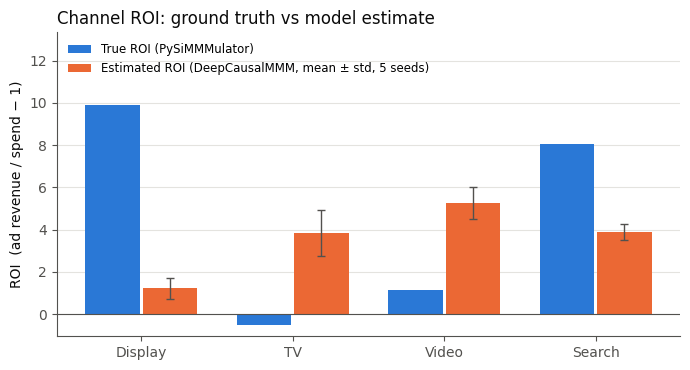

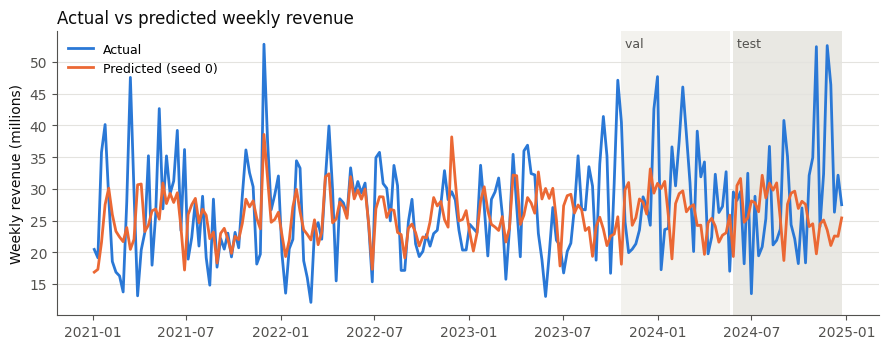

In [26]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"          # categorical slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})

# (1) True vs estimated ROI per channel
fig, ax = plt.subplots(figsize=(7, 3.8))
x, w = np.arange(len(CHANNELS)), 0.36
ax.bar(x - w/2 - 0.01, roi["true_roi"], w, color=BLUE, label="True ROI (PySiMMMulator)")
ax.bar(x + w/2 + 0.01, roi["est_mean"], w, yerr=roi["est_std"], color=ORANGE,
       error_kw={"ecolor": MUTED, "capsize": 3, "lw": 1},
       label=f"Estimated ROI (DeepCausalMMM, mean ± std, {len(MODEL_SEEDS)} seeds)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(x, CHANNELS); ax.set_ylabel("ROI  (ad revenue / spend − 1)")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
top = max(roi["true_roi"].max(), (roi["est_mean"] + roi["est_std"]).max())
ax.set_ylim(top=top * 1.35 if top > 0 else 1)      # headroom so the legend never covers a bar
ax.legend(frameon=False, loc="upper left", fontsize=8.5)
ax.set_title("Channel ROI: ground truth vs model estimate", loc="left", color=INK)
fig.tight_layout(); fig.savefig(PROJECT_DIR / "roi_true_vs_estimated.png", dpi=200); plt.show()

# (2) Actual vs predicted weekly revenue (seed with median holdout R²)
med_seed = fit["test_R2"].sort_values().index[len(fit) // 2]
pred_all = np.concatenate([runs[med_seed]["preds"][k] for k in ["train", "val", "test"]])
fig, ax = plt.subplots(figsize=(9, 3.6))
for k, shade in [("val", "#f3f2ee"), ("test", "#e9e8e3")]:
    s = splits[k]
    ax.axvspan(weekly.index[s.start], weekly.index[s.stop - 1], color=shade, lw=0)
    ax.text(weekly.index[s.start], 0.98, f" {k}", transform=ax.get_xaxis_transform(),
            va="top", color=MUTED, fontsize=9)
ax.plot(weekly.index, y[0] / 1e6, color=BLUE, lw=2, label="Actual")
ax.plot(weekly.index, pred_all / 1e6, color=ORANGE, lw=2, label=f"Predicted (seed {med_seed})")
ax.set_ylabel("Weekly revenue (millions)"); ax.grid(axis="y", color=GRID, lw=0.8)
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_title("Actual vs predicted weekly revenue", loc="left", color=INK)
fig.tight_layout(); fig.savefig(PROJECT_DIR / "actual_vs_predicted.png", dpi=200); plt.show()

## 6. Results summary, negative results and limitations

The cell below prints a plain-text summary for the report. Interpret it with these points in mind:
- **Negative results count** (proposal): if a channel's estimated ROI is far from the truth, or its rank is
  wrong, report it as-is.
- **Synthetic data limitation** (proposal [14]): the simulator's data-generating process is clean
  (known adstock/Hill forms, little noise), so results here are an upper bound on what to expect from real data.
- **Share-of-voice scaling:** DeepCausalMMM feeds the model each channel's *share* of total spend per week,
  not the spend level. In this data the shares barely move (std ≈ 0.01–0.04), while revenue is driven by
  spend *levels*, so channel effects are weakly identified. This is the most likely cause of poor ROI recovery.
- **Trend:** in deepcausalmmm 1.0.21 the model's trend term is frozen at zero, so the upward trend can only
  enter through the time-index control. The model therefore tends to under-predict the later (holdout) weeks.
- **Holdout R² on a short window:** the holdout is ~31 weeks with little variance around a high level, so a
  level offset drives R² negative even when the RMSE is moderate. Report RMSE as a % of mean revenue alongside it.
- **Segment-wise evaluation:** each split is run as its own sequence with burn-in padding, the same way the
  package's trainer evaluates holdouts, so the first weeks of val/test start from a cold GRU state.
- **Single dataset:** the seeds vary model initialisation, not the simulated data. To test robustness to the
  data itself, re-run with different `DATA_SEED` values (true ROI changes with it).

In [27]:
import platform
versions = {"python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__,
            "pandas": pd.__version__, **{p: installed(p) for p in PINS}, "device": DEVICE}
json.dump(versions, open(PROJECT_DIR / "versions.json", "w"), indent=2)

lines = [
    "MMM extension — DeepCausalMMM on PySiMMMulator synthetic data",
    f"Data: {T} weeks, {len(CHANNELS)} channels ({', '.join(CHANNELS)}), DATA_SEED={DATA_SEED}",
    f"Split: train {n_train} / val {n_val} / holdout {n_test} weeks (chronological)",
    f"Seeds: {MODEL_SEEDS}",
    "",
    f"Holdout R²:   {summary.loc['test_R2', 'mean']:.3f} ± {summary.loc['test_R2', 'std']:.3f}",
    f"Holdout RMSE: {summary.loc['test_RMSE', 'mean']:,.0f} ± {summary.loc['test_RMSE', 'std']:,.0f} "
    f"({summary.loc['test_RMSE', 'mean'] / holdout_mean:.1%} of mean holdout weekly revenue)",
    f"Train R²:     {summary.loc['train_R2', 'mean']:.3f} ± {summary.loc['train_R2', 'std']:.3f}",
    "",
    "Channel ROI (true vs estimated, mean ± std over seeds):",
    *[f"  {c:<8} true {roi.loc[c, 'true_roi']:>7.3f} | est {roi.loc[c, 'est_mean']:>7.3f} ± "
      f"{roi.loc[c, 'est_std']:.3f} | abs err {roi.loc[c, 'abs_error']:.3f}" for c in CHANNELS],
    f"Mean abs ROI error {roi['abs_error'].mean():.3f}; Spearman rank agreement {rho:.2f}",
    "",
    f"Versions: {versions}",
]
text = "\n".join(lines)
(PROJECT_DIR / "results_summary.txt").write_text(text)
print(text)
print("\nSaved files:", sorted(p.name for p in PROJECT_DIR.iterdir()))

MMM extension — DeepCausalMMM on PySiMMMulator synthetic data
Data: 208 weeks, 4 channels (Display, TV, Video, Search), DATA_SEED=42
Split: train 146 / val 31 / holdout 31 weeks (chronological)
Seeds: [0, 1, 2, 3, 4]

Holdout R²:   -0.622 ± 0.044
Holdout RMSE: 11,948,581 ± 161,370 (41.3% of mean holdout weekly revenue)
Train R²:     0.103 ± 0.006

Channel ROI (true vs estimated, mean ± std over seeds):
  Display  true   9.878 | est   1.221 ± 0.500 | abs err 8.658
  TV       true  -0.531 | est   3.832 ± 1.089 | abs err 4.363
  Video    true   1.141 | est   5.254 ± 0.764 | abs err 4.112
  Search   true   8.030 | est   3.896 ± 0.382 | abs err 4.134
Mean abs ROI error 5.317; Spearman rank agreement -0.40

Versions: {'python': '3.13.16', 'torch': '2.11.0+cpu', 'numpy': '1.26.4', 'pandas': '2.2.3', 'pysimmmulator': '0.6.2', 'deepcausalmmm': '1.0.21', 'device': 'cpu'}

Saved files: ['actual_vs_predicted.png', 'deepcausalmmm_seed0.pt', 'deepcausalmmm_seed1.pt', 'deepcausalmmm_seed2.pt', 'deepc